### Nama : A.Aiman Aziiz Danial
### Nim  : H061241003

# Guided Recipes: Dari Gagasan ke Recipe yang Dapat Dipakai Ulang
## Studi kasus recipe buatan sendiri **R-ERT-001** (Screening Anomali ERT-IP)

Mata kuliah Kecerdasan AI Geofisika. Acuan: buku *AI Cookbook untuk Earth Sciences*, Chapter 4 "Membuat Recipe dengan Bantuan AI" (hlm. 73-78).

## 1. Tujuan (Learning Outcomes)

Setelah mengerjakan notebook ini, pembaca dapat:

1. mengubah scientific idea menjadi task yang memiliki scope, input, assumption, dan output yang cukup jelas;
2. memakai AI untuk menyusun prompt, implementation outline, dan companion artifact tanpa mengangkat status evidence;
3. memilih mekanisme terkecil yang memadai dan melakukan simplification pass sebelum recipe digunakan ulang.

| Outcome | Dikerjakan pada | Bukti di notebook |
|---|---|---|
| 1. Idea menjadi task | Bagian 4 (Clarify) dan 5 (Specify) | Tabel task specification dan input/output contract |
| 2. AI menyusun artifact tanpa menaikkan status evidence | Bagian 6, 7, 11 | Prompt P-ERT-001, script, tabel status evidence |
| 3. Mekanisme terkecil + simplification | Bagian 10 | Tabel pemilihan mekanisme, audit dependency |

**Tugas dari dosen:** (a) cek resep buku lalu implementasikan, (b) bila belum ada, buat resep sendiri. Jawabannya ada di Bagian 3 (cek buku) dan Bagian 4-10 (resep sendiri).

## 2. Alur Meta-recipe (Gambar dari Buku)

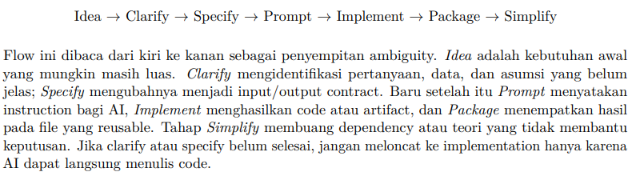

**Gambar 2.1** Alur meta-recipe: Idea → Clarify → Specify → Prompt → Implement → Package → Simplify.

Alur dibaca dari kiri ke kanan sebagai **penyempitan ambiguity**. *Idea* adalah kebutuhan awal yang masih luas; *Clarify* mengidentifikasi pertanyaan, data, dan asumsi yang belum jelas; *Specify* mengubahnya menjadi input/output contract. Baru setelah itu *Prompt* menyatakan instruction bagi AI, *Implement* menghasilkan code atau artifact, dan *Package* menempatkan hasil pada file yang reusable. *Simplify* membuang dependency atau teori yang tidak membantu keputusan. Jika Clarify atau Specify belum selesai, jangan meloncat ke Implement hanya karena AI dapat langsung menulis code.

Notebook ini mengikuti tujuh tahap tersebut secara berurutan.

## 3. Langkah 0: Cek Resep di Buku

Sebelum membuat recipe baru, saya memeriksa buku (424 halaman) pada **daftar recipe** (List of Recipes), **Appendix F (Recipe Catalog)**, dan pencarian kata kunci pada teks.

**Hasil pencarian kata kunci pada teks buku**

| Kata kunci | Jumlah baris | Keterangan |
|---|---|---|
| `geolistrik`, `chargeab`, `induced polar`, `tomograf`, `pyGIMLi` | 0 | tidak dibahas |
| `ERT` / `Electrical Resistivity` | 4 | hanya sebagai contoh prompt QA acquisition (hlm. 20), baris tabel domain *Near-surface geophysics* (hlm. 24), dan glosarium (hlm. 369-370) |

Perintah yang dipakai (dapat diulang):

```bash
pdftotext -layout codex.pdf codex.txt
grep -i -c -E "resistiv|geolistrik|chargeab|induced polar|tomograf|pyGIMLi" codex.txt
```

**Recipe terdekat di buku**

| ID | Judul | Kedekatan | Status di Appendix F |
|---|---|---|---|
| R-QC-001 | Membuat Data Quality Summary | audit data sebelum analisis | specification-only |
| R-CAL-002 | Menghitung Anomaly terhadap Baseline | konsep anomali terhadap baseline | specification-only |
| R-PUB-001 | Membuat Result Manifest | pencatatan hasil dan hash | specification-only |

**Kesimpulan:** buku **belum memiliki recipe ERT/IP**. Karena itu saya membuat recipe sendiri (**R-ERT-001**) dan menautkan ketiga recipe di atas sebagai *related recipes*. Satu petunjuk dari buku dipakai langsung: contoh prompt QA near-surface menyatakan bahwa audit ERT hanya memberi flag dan tidak melakukan interpretasi bawah permukaan. Maka recipe ini memiliki **QC gate** di awal dan membatasi diri pada *screening*, bukan identifikasi mineral.

## 4. Idea → Clarify

**Idea (masih luas):** "Saya ingin menganalisis anomali pada data ERT dan IP."

Kata *menganalisis* terlalu luas. Dengan prompt P-META-001 (Clarify a scientific task), gagasan dipersempit menjadi satu task:

| Komponen | Hasil Clarify |
|---|---|
| Objective | Menandai zona kandidat: (a) resistivitas rendah + chargeability tinggi, (b) resistivitas rendah tanpa chargeability tinggi |
| Required inputs | Tabel blok model inversi 2D: posisi, ukuran blok, resistivitas, chargeability |
| Spatial/temporal scope | Satu lintasan 2D (jarak lintasan lokal, kedalaman positif ke bawah); satu waktu survei |
| Assumptions to confirm | Data sudah hasil inversi yang konvergen; satuan ohm.m dan mV/V; ambang statistik global cukup untuk screening |
| Recommended output | `anomalies.csv`, `report.md`, run record |
| Batas task | Tidak inversi ulang, tidak menyimpulkan jenis mineral, tidak mengubah input |

**Pertanyaan klarifikasi (maksimal tiga, hanya yang mengubah method)** beserta asumsi bawaan yang saya pakai:

1. Apakah ada data bor/geologi untuk verifikasi? → *Asumsi: tidak ada*; verifikasi hanya uji sensitivitas internal.
2. Ambang absolut (dari literatur lokasi) atau statistik? → *Asumsi: statistik*, dapat diganti lewat file konfigurasi.
3. Apakah resistivitas memiliki tren kedalaman kuat? → *Asumsi: diabaikan*, dicatat sebagai limitation.

## 5. Specify: Input/Output Contract

| Aspek | Kontrak |
|---|---|
| Input | `data/samples/ert-ip-model-example.csv` dengan kolom `x_center_m`, `depth_center_m`, `dx_m`, `dz_m`, `resistivity_ohm_m`, `chargeability_mv_v` |
| Satuan/konvensi | ohm.m, mV/V, meter; jarak = jarak lintasan lokal (tanpa CRS); kedalaman positif ke bawah |
| Provenance | Fixture **sintetis** (`make_fixture.py`, seed 42), bukan data lapangan |
| Konfigurasi | `artifacts/configurations/r-ert-001.json` (faktor ambang, jumlah blok minimum) |
| Output | `anomalies.csv`, `sensitivity.csv`, `report.md` pada `results/ert/example-run/`; run record pada `results/run-records/` |
| Perilaku gagal | Resistivitas <= 0, kolom hilang, atau blok duplikat → berhenti dengan exit code 2, tanpa output |
| Acceptance criteria | Check pada run record lolos; output memenuhi `artifacts/expected-outputs/r-ert-001.json` |

In [1]:
from pathlib import Path

ROOT = Path.cwd()
assert (ROOT / "artifacts").exists(), "Jalankan notebook dari root repo (folder yang berisi artifacts/, code/, data/)"

INPUT = "data/samples/ert-ip-model-example.csv"
lines = (ROOT / INPUT).read_text(encoding="utf-8").splitlines()
print(f"{INPUT}: {len(lines) - 1} baris data")
print("\n".join(lines[:5]))

data/samples/ert-ip-model-example.csv: 360 baris data
x_center_m,depth_center_m,dx_m,dz_m,resistivity_ohm_m,chargeability_mv_v
2.5,1.0,5.0,2,148.92,2.862
7.5,1.0,5.0,2,149.17,3.562
12.5,1.0,5.0,2,149.05,1.802
17.5,1.0,5.0,2,152.51,2.786


## 6. Prompt

Prompt disusun dengan struktur dari tugas sebelumnya (Role, Task, Context, Input, Constraints, Output, Quality criteria, Verification) dan placeholder `[LIKE_THIS]` sesuai P-META-002. Prompt disimpan sebagai companion file **P-ERT-001**.

In [2]:
print((ROOT / "artifacts/prompts/ert/p-ert-001.md").read_text(encoding="utf-8"))

# P-ERT-001 — Screening anomali ERT-IP dari tabel model inversi

- **Recipe terkait:** R-ERT-001
- **Struktur:** Role, Task, Context, Input, Constraints, Output, Quality criteria, Verification
- **Status:** illustrative — prompt ini instruction, bukan bukti bahwa code sudah dijalankan.

## Prompt

```text
ROLE:
Bertindaklah sebagai geofisikawan eksplorasi near-surface yang memahami model hasil inversi ERT dan IP.

TASK:
Tandai zona kandidat anomali pada tabel model inversi [INPUT_CSV]: (a) resistivitas rendah dengan chargeability tinggi,
dan (b) resistivitas rendah tanpa chargeability tinggi. Tulis hasilnya sebagai tabel zona dan report singkat.

CONTEXT:
Lintasan [PANJANG_LINTASAN_M] m, spasi elektroda [SPASI_M] m, kedalaman model maksimum [DOI_M] m.
Output dipakai untuk menentukan prioritas pengecekan lanjutan, bukan untuk menyimpulkan mineral.

INPUT:
File [INPUT_CSV] dengan kolom x_center_m, depth_center_m, dx_m, dz_m, resistivity_ohm_m, chargeability_mv_v.
Konfigurasi ambang pada 

## 7. Implement

Dengan prompt gaya P-META-003, implementasi dipilih **sesederhana mungkin**: Python standard library saja, fungsi terpisah untuk input, perhitungan, dan output, serta tanpa framework tambahan. Source lengkap: `code/recipes/ert/r-ert-001.py`.

**Daftar fungsi pada script**

In [3]:
script = ROOT / "code/recipes/ert/r-ert-001.py"
for n, line in enumerate(script.read_text(encoding="utf-8").splitlines(), start=1):
    if line.startswith("def "):
        print(f"baris {n:>3}: {line.split('(')[0][4:]}")

baris  30: sha256
baris  39: load_model
baris  59: validate
baris  74: thresholds
baris  82: classify
baris  88: zones
baris 127: sensitivity
baris 149: write_csv
baris 157: write_report
baris 190: main


**Menjalankan recipe** (command yang sama dengan Quick Start pada README)

In [4]:
import subprocess, sys

cmd = [sys.executable, "code/recipes/ert/r-ert-001.py",
       "--input", "data/samples/ert-ip-model-example.csv",
       "--config", "artifacts/configurations/r-ert-001.json",
       "--outdir", "results/ert/example-run",
       "--run-record", "results/run-records/r-ert-001.json"]
proc = subprocess.run(cmd, cwd=ROOT, capture_output=True, text=True)
print("exit status :", proc.returncode)
print("stdout      :", proc.stdout.strip())
print("stderr      :", proc.stderr.strip() or "(kosong)")

exit status : 0
stdout      : Selesai: 2 zona | laporan: results/ert/example-run/report.md
stderr      : (kosong)


**Report yang dihasilkan (`report.md`)**

In [5]:
print((ROOT / "results/ert/example-run/report.md").read_text(encoding="utf-8"))

# Report R-ERT-001: Screening Anomali ERT-IP

- Input: `data/samples/ert-ip-model-example.csv` (360 blok)
- Provenance: Fixture sintetis dari code/recipes/ert/make_fixture.py (seed=42); bukan data lapangan
- Konfigurasi: `artifacts/configurations/r-ert-001.json`

## Ambang (diturunkan dari statistik data)

- Median resistivitas: 278.1 ohm.m; ambang rendah < 83.4 ohm.m (0.30 x median)
- Chargeability: rata-rata 4.28, SD 6.48 mV/V; ambang tinggi > 17.23 mV/V (rata-rata + 2.0 SD)

## Zona terdeteksi

| Zona | Kelas | x (m) | Kedalaman (m) | rho rata-rata geometrik (ohm.m) | IP rata-rata (mV/V) | Blok |
|---|---|---|---|---|---|---|
| A1 | candidate_conductive_polarizable | 95-120 | 15.0-30.0 | 20.6 | 37.5 | 13 |
| B1 | conductive_nonpolarizable | 30-50 | 0.0-4.5 | 41.3 | 4.9 | 6 |

## Uji sensitivitas ambang (optional check)

Zona kandidat terbesar muncul pada 20 dari 20 kombinasi ambang (100 %).

## Batas interpretasi

- Ini screening statistik pada model hasil inversi, bukan identifikas

**Visualisasi hasil** (hanya di notebook; script recipe tidak bergantung pada library gambar)

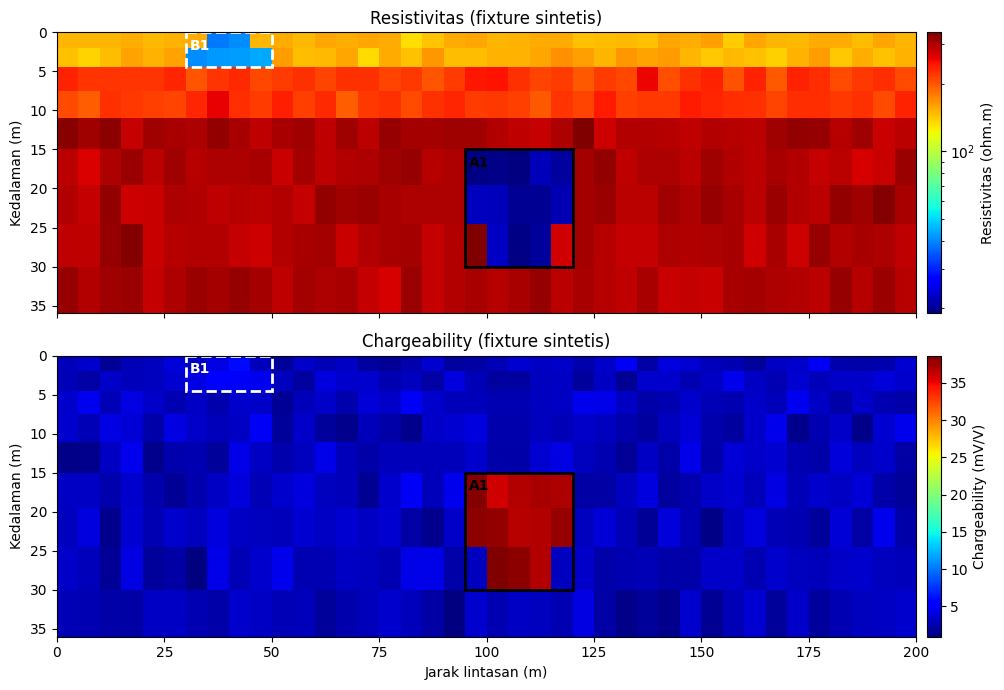

In [6]:
import csv
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle

with open(ROOT / INPUT, encoding="utf-8") as f:
    rows = [{k: float(v) for k, v in r.items()} for r in csv.DictReader(f)]
ux = sorted({r["x_center_m"] for r in rows})
uz = sorted({r["depth_center_m"] for r in rows})
dx = {r["x_center_m"]: r["dx_m"] for r in rows}
dz = {r["depth_center_m"]: r["dz_m"] for r in rows}
x_edges = [ux[0] - dx[ux[0]] / 2] + [x + dx[x] / 2 for x in ux]
z_edges = [uz[0] - dz[uz[0]] / 2] + [z + dz[z] / 2 for z in uz]
rho = [[0.0] * len(ux) for _ in uz]
ip = [[0.0] * len(ux) for _ in uz]
for r in rows:
    j, i = ux.index(r["x_center_m"]), uz.index(r["depth_center_m"])
    rho[i][j], ip[i][j] = r["resistivity_ohm_m"], r["chargeability_mv_v"]

with open(ROOT / "results/ert/example-run/anomalies.csv", encoding="utf-8") as f:
    zones = list(csv.DictReader(f))

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
p1 = ax[0].pcolormesh(x_edges, z_edges, rho, cmap="jet", norm=LogNorm())
p2 = ax[1].pcolormesh(x_edges, z_edges, ip, cmap="jet")
fig.colorbar(p1, ax=ax[0], label="Resistivitas (ohm.m)", pad=0.01)
fig.colorbar(p2, ax=ax[1], label="Chargeability (mV/V)", pad=0.01)
ax[0].set_title("Resistivitas (fixture sintetis)")
ax[1].set_title("Chargeability (fixture sintetis)")
for a in ax:
    for z in zones:
        kand = z["class"].startswith("candidate")
        a.add_patch(Rectangle((float(z["x_min_m"]), float(z["depth_top_m"])),
                              float(z["x_max_m"]) - float(z["x_min_m"]),
                              float(z["depth_bottom_m"]) - float(z["depth_top_m"]),
                              fill=False, lw=2, ec="black" if kand else "white", ls="-" if kand else "--"))
        a.text(float(z["x_min_m"]) + 1, float(z["depth_top_m"]) + 2.2, z["zone_id"],
               color="black" if kand else "white", fontsize=10, fontweight="bold")
    a.invert_yaxis()
    a.set_ylabel("Kedalaman (m)")
ax[1].set_xlabel("Jarak lintasan (m)")
plt.tight_layout()
(ROOT / "figures/ert").mkdir(parents=True, exist_ok=True)
plt.savefig(ROOT / "figures/ert/example-run.png", dpi=130, bbox_inches="tight")
plt.show()

## 8. Verifikasi

Dua pemeriksaan: (1) **QC gate** harus menolak input yang salah, dan (2) hasil aktual harus memenuhi **expected output** serta hash pada run record. Ingat: *expected output bukan hasil aktual*; keduanya dibandingkan, bukan disamakan.

In [7]:
# 1) Uji QC gate: salin input lalu rusak satu nilai resistivitas menjadi negatif
import tempfile

bad_dir = Path(tempfile.mkdtemp())
bad = bad_dir / "bad.csv"
lines = (ROOT / INPUT).read_text(encoding="utf-8").splitlines()
cols = lines[1].split(",")
cols[4] = "-5.0"
lines[1] = ",".join(cols)
bad.write_text("\n".join(lines) + "\n", encoding="utf-8")

proc = subprocess.run([sys.executable, "code/recipes/ert/r-ert-001.py", "--input", str(bad),
                       "--config", "artifacts/configurations/r-ert-001.json",
                       "--outdir", str(bad_dir / "out")], cwd=ROOT, capture_output=True, text=True)
print("exit status :", proc.returncode, "(harapan: 2)")
print("pesan       :", proc.stderr.strip())
print("output dibuat?", (bad_dir / "out").exists(), "(harapan: False)")

exit status : 2 (harapan: 2)
pesan       : [OK] input_tidak_kosong 360 baris
[GAGAL] resistivitas_positif min=-5.00 ohm.m
[OK] nilai_terhingga 
[OK] ukuran_blok_positif 
[OK] tanpa_blok_duplikat
output dibuat? False (harapan: False)


In [8]:
# 2) Bandingkan hasil aktual dengan expected output dan run record
import hashlib, json

def sha(p):
    return hashlib.sha256((ROOT / p).read_bytes()).hexdigest()

exp = json.loads((ROOT / "artifacts/expected-outputs/r-ert-001.json").read_text(encoding="utf-8"))
rec = json.loads((ROOT / "results/run-records/r-ert-001.json").read_text(encoding="utf-8"))
out = ROOT / "results/ert/example-run"
with open(out / "anomalies.csv", encoding="utf-8") as f:
    rd = csv.DictReader(f)
    cols_actual, zs = rd.fieldnames, list(rd)
with open(out / "sensitivity.csv", encoding="utf-8") as f:
    sens = list(csv.DictReader(f))
report = (out / "report.md").read_text(encoding="utf-8")

cand = [z for z in zs if z["class"].startswith("candidate")]
top = max(cand, key=lambda z: int(z["n_blocks"])) if cand else None
persist = 100 * sum(s["found"] == "True" for s in sens) / len(sens)
ex = exp["expectations"]

checks = [
    ("hash input sesuai run record", sha(rec["input"]["path"]) == rec["input"]["sha256"]),
    ("hash semua output sesuai run record", all(sha(o["path"]) == o["sha256"] for o in rec["outputs"])),
    ("semua check pada run record lolos", all(c["passed"] for c in rec["checks"])),
    ("jumlah baris input = ekspektasi", rec["input"]["rows"] == exp["input"]["rows"]),
    ("kolom anomalies.csv = ekspektasi", cols_actual == exp["anomalies_csv_columns"]),
    ("seksi report lengkap", all(s in report for s in exp["required_report_sections"])),
    ("zona kandidat >= minimum", len(cand) >= ex["min_candidate_zones"]),
    ("centroid x zona kandidat terbesar dalam rentang",
     top is not None and ex["largest_candidate_centroid_x_m"][0] <= float(top["centroid_x_m"]) <= ex["largest_candidate_centroid_x_m"][1]),
    ("centroid kedalaman dalam rentang",
     top is not None and ex["largest_candidate_centroid_depth_m"][0] <= float(top["centroid_depth_m"]) <= ex["largest_candidate_centroid_depth_m"][1]),
    (f"persistensi sensitivitas >= {ex['min_sensitivity_persistence_percent']} % (aktual {persist:.0f} %)",
     persist >= ex["min_sensitivity_persistence_percent"]),
]
for name, ok in checks:
    print(f"[{'LOLOS' if ok else 'GAGAL'}] {name}")
print()
print("Status:", "semua check lolos" if all(ok for _, ok in checks) else "ADA CHECK GAGAL")
print("Catatan: check ini hanya membuktikan kesesuaian dengan kontrak pada fixture sintetis, bukan kebenaran ilmiah.")

[LOLOS] hash input sesuai run record
[LOLOS] hash semua output sesuai run record
[LOLOS] semua check pada run record lolos
[LOLOS] jumlah baris input = ekspektasi
[LOLOS] kolom anomalies.csv = ekspektasi
[LOLOS] seksi report lengkap
[LOLOS] zona kandidat >= minimum
[LOLOS] centroid x zona kandidat terbesar dalam rentang
[LOLOS] centroid kedalaman dalam rentang
[LOLOS] persistensi sensitivitas >= 80 % (aktual 100 %)

Status: semua check lolos
Catatan: check ini hanya membuktikan kesesuaian dengan kontrak pada fixture sintetis, bukan kebenaran ilmiah.


## 9. Package

Recipe dikemas dalam struktur companion file dari buku (Bagian 2.7): prompt, recipe specification, configuration, expected output, source, input, hasil, dan run record, masing-masing dengan **stable ID** `R-ERT-001` / `P-ERT-001`.

**Isi repository**

In [9]:
import os

skip = {".git", ".ipynb_checkpoints", "__pycache__"}
for base, dirs, files in os.walk(ROOT):
    dirs[:] = sorted(d for d in dirs if d not in skip)
    for name in sorted(files):
        p = Path(base) / name
        print(f"{str(p.relative_to(ROOT)):<58}{p.stat().st_size:>9,} B")

.gitignore                                                       85 B
Guided_Recipes_ERT_IP.ipynb                                 152,984 B
README.md                                                     2,656 B
artifacts/configurations/r-ert-001.json                         492 B
artifacts/expected-outputs/r-ert-001.json                       888 B
artifacts/prompts/ert/p-ert-001.md                            2,478 B
artifacts/recipes/ert/r-ert-001.md                            4,154 B
code/recipes/ert/make_fixture.py                              1,959 B
code/recipes/ert/r-ert-001.py                                11,852 B
data/samples/ert-ip-model-example.csv                        11,445 B
figures/meta-recipe-flow.png                                 94,774 B
figures/ert/example-run.png                                  67,289 B
results/ert/example-run/anomalies.csv                           343 B
results/ert/example-run/report.md                             1,290 B
results/ert/example-

**Run record** (bukti eksekusi: command, exit status, environment, hash, check, batas eksekusi)

In [10]:
short = lambda h: h[:12] + "..."
view = {
    "recipe_id": rec["recipe_id"], "prompt_id": rec["prompt_id"], "status": rec["status"],
    "command": " ".join(rec["command"]), "exit_status": rec["exit_status"],
    "environment": rec["environment"],
    "input": {**rec["input"], "sha256": short(rec["input"]["sha256"])},
    "outputs": [{"path": o["path"], "sha256": short(o["sha256"])} for o in rec["outputs"]],
    "checks": [f"{c['name']}: {'lolos' if c['passed'] else 'GAGAL'}" for c in rec["checks"]],
    "execution_boundary": rec["execution_boundary"],
}
print(json.dumps(view, indent=2, ensure_ascii=False))

{
  "recipe_id": "R-ERT-001",
  "prompt_id": "P-ERT-001",
  "status": "executed locally; fixture sintetis; bukan bukti lapangan",
  "command": "python code/recipes/ert/r-ert-001.py --input data/samples/ert-ip-model-example.csv --config artifacts/configurations/r-ert-001.json --outdir results/ert/example-run --run-record results/run-records/r-ert-001.json",
  "exit_status": 0,
  "environment": {
    "python": "3.12.3",
    "platform": "Linux-6.18.44-fc-v139-x86_64-with-glibc2.39",
    "dependencies": "standard library saja"
  },
  "input": {
    "path": "data/samples/ert-ip-model-example.csv",
    "sha256": "07bfb12fd329...",
    "rows": 360,
    "provenance": "Fixture sintetis dari code/recipes/ert/make_fixture.py (seed=42); bukan data lapangan"
  },
  "outputs": [
    {
      "path": "results/ert/example-run/anomalies.csv",
      "sha256": "bcd6caa403d5..."
    },
    {
      "path": "results/ert/example-run/sensitivity.csv",
      "sha256": "05931a119b35..."
    },
    {
      "path"

## 10. Simplify

### 10.1 Memilih mekanisme terkecil (R-META-004)

| Mekanisme | Perlu? | Alasan |
|---|---|---|
| Direct prompt | Tidak cukup | Task menghasilkan beberapa file, check, dan run record yang harus diwariskan |
| **Recipe (prompt + script + config + run record)** | **Dipilih** | Satu problem sempit, procedure akan diulang pada lintasan lain |
| Skill | Belum | Upgrade path bila recipe dipakai berulang lintas project (R-AI-001) |
| MCP | Tidak | Tidak ada kebutuhan akses eksternal; data lokal |
| Plugin/connector | Tidak | Tidak ada kebutuhan distribusi atau integrasi layanan |

### 10.2 Simplification pass

| Dibuang atau ditunda | Alasan |
|---|---|
| pyGIMLi / inversi ulang | Task hanya men-screening model yang sudah ada |
| NumPy dan SciPy | Standard library cukup; komponen terhubung memakai BFS sederhana |
| Smoothing Gaussian pada fixture (tugas sebelumnya) | Tidak mengubah keputusan; noise kecil sudah cukup |
| Plot di dalam script | Gambar hanya di notebook, sehingga script tanpa dependency |
| SQLite, database, framework web | Tidak ada kebutuhan query atau layanan |
| Teori resistivitas panjang | Cukup satu kotak Minimal Theory (E-ERT-001) |
| Check tanpa pembanding eksternal | Verifikasi bor tidak tersedia; tidak dibuat-buat |
| **Dipertahankan:** uji sensitivitas ambang | Ambang arbitrer dan menentukan hasil, sehingga check ini sebanding dengan risikonya |

**Audit nyata: apakah script hanya memakai standard library?**

In [11]:
import ast

tree = ast.parse(script.read_text(encoding="utf-8"))
mods = set()
for node in ast.walk(tree):
    if isinstance(node, ast.Import):
        mods |= {a.name.split(".")[0] for a in node.names}
    elif isinstance(node, ast.ImportFrom):
        mods.add(node.module.split(".")[0])
n_lines = len(script.read_text(encoding="utf-8").splitlines())
n_funcs = sum(isinstance(n, ast.FunctionDef) for n in ast.walk(tree))
print("module yang diimpor :", sorted(mods))
print("semuanya stdlib     :", all(m in sys.stdlib_module_names for m in mods))
print(f"ukuran script       : {n_lines} baris, {n_funcs} fungsi")

module yang diimpor : ['argparse', 'collections', 'csv', 'datetime', 'hashlib', 'json', 'math', 'pathlib', 'platform', 'statistics', 'sys']
semuanya stdlib     : True
ukuran script       : 248 baris, 10 fungsi


## 11. Review dan Status Evidence

### 11.1 Review recipe (rubric Bagian 4.5: contract, bukan kelancaran prose)

| Pertanyaan review | Evidence | Hasil self-review |
|---|---|---|
| Problem dan intended use dinyatakan? | `r-ert-001.md` bagian Problem | Terpenuhi |
| Input, unit, konvensi, assumption dapat ditelusuri? | Bagian 5, `r-ert-001.json` | Terpenuhi |
| Constraints dan approval dinyatakan? | Prompt P-ERT-001 (tanpa ubah input, tanpa jaringan) | Terpenuhi |
| Output dan acceptance criteria dapat diperiksa? | Expected output + 10 check pada Bagian 8 | Terpenuhi |
| Limitation tidak tertutup ringkasan hasil? | `report.md` bagian Batas interpretasi | Terpenuhi |
| Expected output dibedakan dari actual result? | File terpisah; dibandingkan pada Bagian 8 | Terpenuhi |

### 11.2 Status evidence (tidak dinaikkan oleh bantuan AI)

| Artifact | Status | Alasan |
|---|---|---|
| Prompt P-ERT-001 | illustrative | Instruction, bukan bukti eksekusi |
| Recipe specification R-ERT-001 | documented specification | Bergantung pada run record untuk bukti |
| Script `r-ert-001.py` | executed locally, **fixture sintetis** | Ada command, exit status 0, hash, dan check pada run record |
| Hasil screening (zona A1, B1) | berlaku untuk fixture saja | Bukan bukti lapangan |
| Interpretasi jenis mineral | **tidak dilakukan** | Di luar batas task |
| Verifikasi data bor | **belum** | Data tidak tersedia |
| Eksekusi pada data lapangan | **belum** | Next action: ganti input dengan model inversi riil dan ulangi |

### 11.3 Yang harus diperiksa sendiri oleh pengguna (peran manusia)

- [ ] Asumsi ilmiah: apakah ambang `0.30 x median` dan `rata-rata + 2 SD` masuk akal untuk lokasi Anda?
- [ ] Interpretasi fisis: apakah pasangan resistivitas rendah + chargeability tinggi sesuai geologi lokasi?
- [ ] Data riil: RMS misfit inversi dan kedalaman investigasi (DOI) sudah diperiksa?
- [ ] Kesesuaian dengan rubrik dosen sebelum recipe dianggap selesai.

## 12. Catatan Penutup

Notebook ini menunjukkan satu putaran lengkap alur **Idea → Clarify → Specify → Prompt → Implement → Package → Simplify**:

- buku dicek lebih dulu dan **tidak memiliki recipe ERT/IP**, sehingga dibuat recipe sendiri **R-ERT-001**;
- setiap tahap meninggalkan artifact yang dapat diperiksa (task specification, contract, prompt, script, config, expected output, run record);
- bantuan AI dipakai untuk menyusun draft prompt dan script, sedangkan **status evidence tetap dinyatakan apa adanya**: hasil hanya berlaku pada fixture sintetis;
- mekanisme dipilih sekecil mungkin (recipe, standard library saja) dan disederhanakan sebelum dipakai ulang.

Langkah berikutnya: jalankan pada model inversi riil dan tinjau asumsi sebelum recipe dipakai ulang.